In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.datasets as datasets
import random

import torchvision.transforms as transforms
from torchvision.transforms import v2
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
from torch.utils.data import random_split


import math
import time
import numpy as np 
%matplotlib inline
import matplotlib.pyplot as plt 

import itertools
import pandas as pd

# Downloading data 

Run the code block below to download all the data you need for task 1 and 2 (took me like 20 minutes for the CIFAR10 datasets, but the other ones were pretty quick)

To (un)comment multiple lines: CTRL + /

Please leave it uncommented after using, so we don't have to download all the data again when we rerun the notebook

In [ ]:
# # Download the CIFAR datasets
# cifar10_train = datasets.CIFAR10(root = "./data", train = True, download = True)
# cifar10_test = datasets.CIFAR10(root = "./data", train = False, download = True)

# # Download Fashion-MNIST datasets
# fashion_train = datasets.FashionMNIST(root = "./data", train = True, download = True)
# fashion_test = datasets.FashionMNIST(root = "./data", train = False, download = True)

# # Download time datasets (Task 2)
# import os
# from urllib.request import urlretrieve
# import zipfile

# urls = ["https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_75.zip", 
#         "https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_150.zip"]

# target_folder = "./data"

# for url in urls:
#     file_name = os.path.basename(url)
#     full_path = os.path.join(target_folder, file_name)

#     # Create separate folder for each dataset 
#     dataset_name = os.path.splitext(file_name)[0]
#     extract_folder = os.path.join(target_folder, dataset_name)
#     os.makedirs(extract_folder, exist_ok = True)

#     # Download zip file
#     urlretrieve(url, full_path)

#     # Extract zip file
#     with zipfile.ZipFile(full_path, "r") as zip_ref:
#         zip_ref.extractall(extract_folder)

#     # Remove ZIP file
#     os.remove(full_path)

# Task 1

## Fashion MNIST

### Processing

**Loading data: train, validation, test**

In [8]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
fashion_train_all = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

fashion_test = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

# Split 10% of training data for the validation set
train_size = int(0.9 * len(fashion_train_all))
validation_size = len(fashion_train_all) - train_size

fashion_train, fashion_validation = random_split(
    fashion_train_all,
    [train_size, validation_size],
    generator = torch.Generator().manual_seed(67) # (our group number)
)

**Visualise**

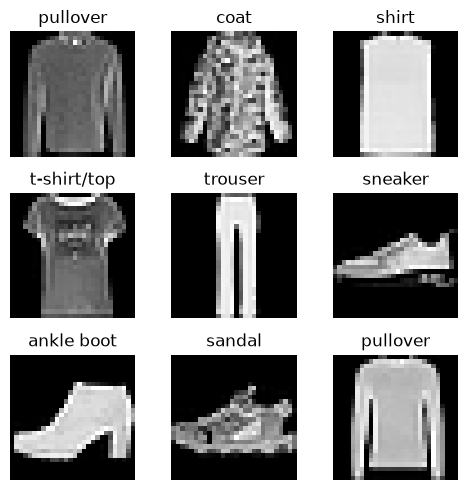

In [9]:
# Define class names
fashion_names = {
    0: "t-shirt/top",
    1: "trouser",
    2: "pullover",
    3: "dress",
    4: "coat",
    5: "sandal",
    6: "shirt",
    7: "sneaker",
    8: "bag",
    9: "ankle boot"
}

# Visualise 
n = 3

fig, ax = plt.subplots(n, n, figsize = (5, 5))

for i in range(n):
    for j in range(n):
        image, label = fashion_train[i * n + j] 
        image_np = image.numpy().squeeze() # Convert image tensor to numpy array
        ax[i, j].imshow(image_np, cmap = "gray")
        ax[i, j].axis("off")
        ax[i, j].set_title(fashion_names[label])
plt.tight_layout()
plt.show()

**Dataloader** (for more efficient processing)

Shuffling doesn't really matter for the validation and test set. Only changes the order of things, but if you take the average it should be the same regardless of order

In [10]:
batch_size = 64

fashion_train_loader = DataLoader(fashion_train, batch_size = batch_size, shuffle = True)
fashion_validation_loader = DataLoader(fashion_validation, batch_size = batch_size, shuffle = False)
fashion_test_loader = DataLoader(fashion_test, batch_size = batch_size, shuffle = False)

In [11]:
print(f"Number of batches in the training DataLoader: {len(fashion_train_loader)}")
print(f"Number of batches in the validation DataLoader: {len(fashion_validation_loader)}")
print(f"Number of batches in the test DataLoader: {len(fashion_test_loader)}")
images, labels = next(iter(fashion_train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Number of batches in the training DataLoader: 844
Number of batches in the validation DataLoader: 94
Number of batches in the test DataLoader: 157
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Image data type: torch.float32
Pixel range: 0.0 1.0


### Model building

NOTES
* The amount of hidden layers and nodes I choose for them feels rather arbitrary. I just followed along with the values from the tutorial but idk if there would be a good reasoning for it

In [12]:
# Hardware device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [13]:
# Class to create a neural network
class NeuralNetwork(nn.Module):
    def __init__(self, 
            model_type = "MLP", # type of model to create (MLP or CNN)
            in_channels = 1, # number of input channels (1 for grayscale images)
            image_size = 28, # size of the input image (28x28 for FashionMNIST)
            hidden_dims = [128, 64], # list of hidden dimensions for MLP
            cnn_channels = [16, 32], # list of convolutional channels for CNN
            kernel_size=3, #size of the convolutional kernel for CNN
            pool_size=2, #size of the pooling kernel for CNN
            stride=2, #stride for pooling for CNN
            activation=nn.ReLU, #activation function
            initialization=None, #weight initialization method
            dropout=0.0 #dropout rate
            ):   
         
        super().__init__() 
        self.model_type = model_type

        #---------------Build the MLP model---------------
        if model_type == "MLP":
            # Create the layers 
            layers = [nn.Flatten()]
            input_size = in_channels * image_size * image_size # Amount of pixels we have

            for hidden_size in hidden_dims:
                layers.append(nn.Linear(input_size, hidden_size))
                layers.append(activation())

                if dropout > 0:
                    layers.append(nn.Dropout(dropout))

                input_size = hidden_size # Change input size, so each layer connects to the next one

            layers.append(nn.Linear(input_size, 10)) # Last layer (output: 10, because we have 10 classes)

            # Combine all our layers into a network
            self.network = nn.Sequential(*layers)# asterisk transforms the list into positional arguments

        #---------------Build the CNN model---------------
        elif model_type == "CNN":
            # Convolutional layers
            feature_layers = []
            current_size = image_size
            for conv_block in range(len(cnn_channels)): # we iterate over the number of convolutional blocks
                in_ch = in_channels if conv_block == 0 else cnn_channels[conv_block - 1]#if conv_block == 0, we use the input channels, otherwise we use the output channels of the previous layer
                out_ch = cnn_channels[conv_block]
                
                feature_layers.append(nn.Conv2d(in_ch, out_ch, kernel_size, padding=kernel_size // 2))# We use padding to keep the output size the same as the input size
                feature_layers.append(activation())
                feature_layers.append(nn.MaxPool2d(kernel_size=pool_size, stride=stride))# We use max pooling to reduce the size of the feature maps
                if dropout > 0:
                    feature_layers.append(nn.Dropout(dropout))

                # MaxPool2d reduces spatial size by stride factor
                current_size = current_size // stride
            # Combine all our layers into a feature extractor
            self.features = nn.Sequential(*feature_layers)

            #Linear Layers
            classifier_layers = [nn.Flatten()]
            input_size = cnn_channels[-1] * current_size * current_size # Last convolutional layer output channels * spatial size of the feature maps
            for hidden_size in hidden_dims:
                classifier_layers.append(nn.Linear(input_size, hidden_size))
                classifier_layers.append(activation())
            
                if dropout > 0:
                    classifier_layers.append(nn.Dropout(dropout))
            
                input_size = hidden_size   

            classifier_layers.append(nn.Linear(input_size, 10)) # Last layer (output: 10, because we have 10 classes)
            # Combine all our layers into a classifier
            self.classifier = nn.Sequential(*classifier_layers)

        # Initialize weights
        if initialization is not None: # Doublecheck that Initilization = None in the baseline model is what the lecturer explained in class
            self.parameter_initializations(initialization)

    def forward(self, x):
        if self.model_type == "MLP":
            return self.network(x)

        elif self.model_type == "CNN":
            x = self.features(x)
            logits = self.classifier(x)
            return logits

    def parameter_initializations(self, name):

        for layer in self.modules():
            if isinstance(layer, (nn.Linear, nn.Conv2d)):

                match name:
                    case "uniform": 
                        nn.init.uniform_(layer.weight)
                    case "xavier":
                        nn.init.xavier_uniform_(layer.weight)
                    case "kaiming":
                        nn.init.kaiming_uniform_(layer.weight, a = 0, mode = "fan_in", nonlinearity = "relu")
                    case "zero": 
                        nn.init.zeros_(layer.weight)
                    case "one":
                        nn.init.ones_(layer.weight)
                    case "normal":
                        nn.init.normal_(layer.weight, mean = 0.0, std = 1)

        
    def create_optimizer(self, name, learning_rate, weight_decay, momentum): # Possibly redundant, see below in def run_experiment.
        optimizer_name = {
            "SGD": optim.SGD,
            "Adam": optim.Adam,
            "AdamW": optim.AdamW
        }

        args = {"lr": learning_rate, "weight_decay": weight_decay}

        if name == "SGD": 
            args["momentum"] = momentum

        # Return the optimizer
        return optimizer_name[name](self.parameters(), **args)


In [14]:
def count_parameters(model, verbose=True):
    total_params = sum(p.numel() for p in model.parameters())
    if verbose:
        print(f"Total Parameters: {total_params:,}")
    return total_params

In [15]:
criterion = nn.CrossEntropyLoss()

def run_experiment(params, train = fashion_train, validation = fashion_validation, 
                   test = fashion_test, plotting = False, seed = 67):
    # 1. Force identical random states for experimental runs (for reproducibility).
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    # Create DataLoaders
    train_loader = DataLoader(train, batch_size = params["batch_size"], shuffle = True)
    validation_loader = DataLoader(validation, batch_size = params["batch_size"], shuffle = False)
    test_loader = DataLoader(test, batch_size = params["batch_size"], shuffle = False)

    # Create the model
    model_params = {key: value for key, value in params.items() 
                    if key not in ("epochs", "batch_size", "optimizer", 
                                   "learning_rate", "momentum", "weight_decay")}
    model = NeuralNetwork(**model_params).to(device)

    # Create optimizer, possibly redundant? We create the optimizer here but also have a class function for it, remove one of two.
    optimizer_name = {
        "SGD": optim.SGD,
        "Adam": optim.Adam,
        "AdamW": optim.AdamW
    }

    args = {"lr": params["learning_rate"], "weight_decay": params["weight_decay"]}

    if params["optimizer"] == "SGD": 
        args["momentum"] = params["momentum"]

    optimizer = optimizer_name[params["optimizer"]](model.parameters(), **args)

    # Store losses and accuracies for each epoch
    history = {
        "train_loss": [0.0] * params["epochs"],
        "val_loss": [0.0] * params["epochs"],
        "train_acc": [0.0] * params["epochs"],
        "val_acc": [0.0] * params["epochs"]
        }

    best_val_loss = np.inf
    best_model_state = None

    for epoch in range(params["epochs"]):
        model.train()


        #---------- Training Phase ----------
        train_loss_total = 0.0
        train_correct_total = 0
        train_total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad() # Clear gradients from the previous step
            
            # Forward pass
            outputs = model(inputs) # Make predictions
            loss = criterion(outputs, labels) # Calculate loss

            # Backward pass 
            loss.backward()  # Calculate gradients
            optimizer.step() # Update weights

            # Training performance
            train_loss_total += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs.data, 1) # Get the index of the max log-probability
            train_correct_total += (predicted == labels).sum().item() # Count the number of correct predictions
            train_total += labels.size(0)

        # Average training loss for this epoch
        history["train_loss"][epoch] = train_loss_total / train_total

        # Average training accuracy for this epoch
        history["train_acc"][epoch] = 100.0 * train_correct_total / train_total

        #---------- Validation Phase ----------
        #Validate after each epoch
        model.eval()
        val_loss_total = 0.0
        val_correct_total = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in validation_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss_total += loss.item() * labels.size(0)

                _, predicted = torch.max(outputs.data, 1)
                val_correct_total += (predicted == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_total / val_total        
        history["val_loss"][epoch] = val_loss
        history["val_acc"][epoch] = 100.0 * val_correct_total / val_total

        # Save model with lowest validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            # Saves model's parameters (cloning tensor onto CPU memory)
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    # Get the best model
    model.load_state_dict(best_model_state)

    #---------- Test Phase ----------
    # Evaluate performance on unseen data (test set)
    test_loss_total = 0.0
    test_correct_total = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss_total += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs.data, 1)
            test_correct_total += (predicted == labels).sum().item()
            test_total += labels.size(0)

    test_loss = test_loss_total / test_total
    # Calculate test accuracy
    test_acc = 100.0 * test_correct_total / test_total

    history["test_acc"] = test_acc

    # Calculate best validation accuracy (from the epoch with lowest val loss)
    best_val_acc = history["val_acc"][np.argmin(history["val_loss"])]


    if plotting:
        epochs_range = range(1, params["epochs"] + 1)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

        # Loss Plot
        ax1.plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
        ax1.plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
        ax1.set_title("Cross-Entropy Loss")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Loss")
        ax1.legend()
        ax1.grid(True) 

        # Accuracy Plot
        ax2.plot(epochs_range, history["train_acc"], marker="o", label="Train Accuracy")
        ax2.plot(epochs_range, history["val_acc"], marker="o", label="Validation Accuracy")
        ax2.set_title("Classification Accuracy (%)")
        ax2.set_xlabel("Epoch")
        ax2.set_ylabel("Accuracy (%)")
        ax2.legend()
        ax2.grid(True) 

        plt.tight_layout()
        plt.show()
    
    return model, history, best_val_loss, best_val_acc, test_loss, test_acc

## Parameters and Testing

Parameters

* Model and architecture
    * model_type: "MLP" or "CNN"
    * hidden_dims: Any list of descending integers
    * channels
    * kernel_size 
* Activation
    * Can be nn.ReLU, nn.LeakyReLU, nn.GELU
    * Also more options (see Session 3 slide 10) nn.Signmoid, nn.Tahn, nn.PReLU, nn.Softplus, nn.SiLU, nn.ELU, nn.SELU 
* Optimizer
    * optimizer: "SGD", "Adam", "AdamW"
    * learning_rate
    * momentum
* Regularization
    * dropout
* Training
    * epochs
    * batch_size


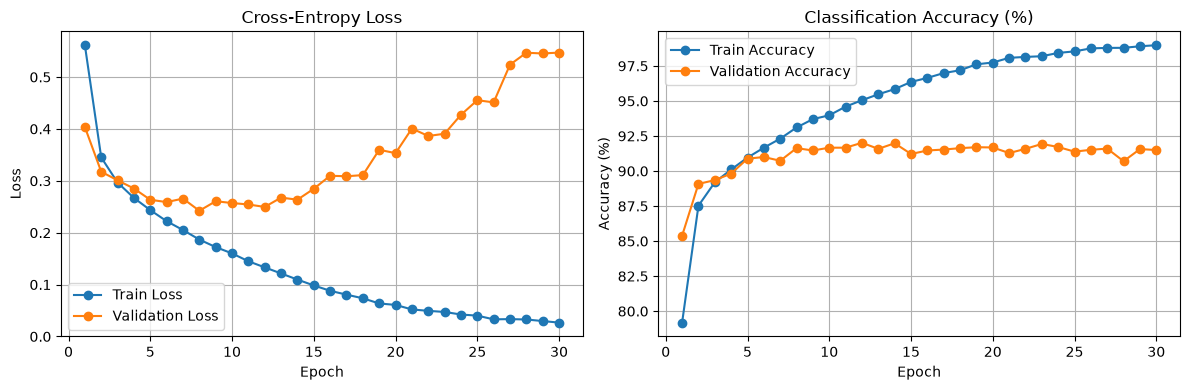


Experiment 1 Results:
NeuralNetwork(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Best Validation Loss: 0.2423|Best Validation Accuracy: 91.63%
Test Loss: 0.2505 | Test Accuracy: 90.97%


In [22]:
params1 = {
    # Model and architecture
    "model_type": "CNN", # "MLP" or "CNN"
    "hidden_dims": [128, 64], 
    "cnn_channels": [16, 32], # Only for CNNs
    "kernel_size": 3, # Only for CNNs
    "pool_size": 2, # Only for CNNs
    "stride": 2, # Only for CNNs

    # Activation
    "activation": nn.ReLU, 

    # Weight initialization
    "initialization": None, # Optional

    # Optimizer
    "optimizer": "AdamW",
    "learning_rate": 0.001, 
    "weight_decay": 0.0, # Optional, regularization
    "momentum": 0.9, # Only if optimizer = "SGD"

    # Regularization
    "dropout": 0.0, # Optional

    # Training
    "epochs": 30,
    "batch_size": 64
}

model1, history1, best_val_loss1,best_val_acc1, test_loss1, test_acc1 = run_experiment(params1, plotting=True)

print("\nExperiment 1 Results:")
print(model1)
print(f"Best Validation Loss: {best_val_loss1:.4f}|Best Validation Accuracy: {best_val_acc1:.2f}%")
print(f"Test Loss: {test_loss1:.4f} | Test Accuracy: {test_acc1:.2f}%")

To choose the number of epochs for the later experiments, we first trained the base MLP and CNN (AdamW, learning rate 0.001, batch size 64) for 30 epochs and monitored the validation loss. More epochs increase computation time and, once the validation loss starts rising, lead to overfitting. The validation loss of the MLP reached its minimum at around epoch 15, and that of the CNN at around epoch 10, after which it increased while the training loss kept falling. We use 15 epochs for both models, so that the comparison between them is fair and the slower MLP is not cut off. Because the weights of the epoch with the lowest validation loss are kept, the extra epochs cost only computation time, not accuracy.

The number of epochs needed also depends on the optimizer and the learning rate: a small learning rate (for example SGD with 0.001) is still improving after 30 epochs with the loss bottoming out between 50 to 60 epochs. A fixed budget of 15 epochs thus penalizes slowly converging configurations. We take this into account when interpreting the results.

### We use parameter grids, in order to find the effect of each Hyperparameter

In [ ]:
    # 1. Define base parameters that remain constant
    base_params = {
        "model_type": "CNN",
        "in_channels": 1,
        "image_size": 28,
        "hidden_dims": [128, 64],
        "activation": nn.ReLU,
        "initialization": None,
        "weight_decay": 0.0,
        "dropout": 0.0,
        "epochs": 15,      # We should keep epochs low during grid search to save time
        "batch_size": 64
    }

    # 2. Define the parameters you want to test
    lr_grid = {
        "SGD":   [0.1, 0.03, 0.01, 0.003, 0.001],
        "AdamW": [0.01, 0.003, 0.001, 0.0003, 0.0001],
    }
    experiment_results = []

    # 3. Loop through all possible combinations

    for opt, lrs in lr_grid.items():
        for lr in lrs:
            print(f"Testing -> Optimizer: {opt} | LR: {lr}")
        
            # Clone base params and inject the current test variables
            current_params = base_params.copy()
            current_params["learning_rate"] = lr
            current_params["optimizer"] = opt
        
            # Handle the momentum edge case (Adam doesn't use standard momentum)
            current_params["momentum"] = 0.9 if opt == "SGD" else 0.0
        

            # We set plotting = False to prevent plot generation.
            model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(
            current_params, 
            plotting=False
            )
        
            # We save the metrics
            experiment_results.append({
                "Optimizer": opt,
                "LR": lr,
                "Dropout": base_params["dropout"],
                "Val Loss": round(val_loss, 4),
                "Val Acc (%)": round(val_acc, 2),
                "Test Acc (%)": round(test_acc, 2)
            })

    # 4. Display the results neatly
    results_df = pd.DataFrame(experiment_results)
    # Sort by highest validation accuracy
    results_df = results_df.sort_values(by="Val Acc (%)", ascending=False).reset_index(drop=True)
    display(results_df)

Testing -> Optimizer: SGD | LR: 0.1
Testing -> Optimizer: SGD | LR: 0.03
Testing -> Optimizer: SGD | LR: 0.01
Testing -> Optimizer: SGD | LR: 0.003
Testing -> Optimizer: SGD | LR: 0.001
Testing -> Optimizer: AdamW | LR: 0.01
Testing -> Optimizer: AdamW | LR: 0.003
Testing -> Optimizer: AdamW | LR: 0.001
Testing -> Optimizer: AdamW | LR: 0.0003
Testing -> Optimizer: AdamW | LR: 0.0001


,Optimizer,LR,Dropout,Val Loss,Val Acc (%),Test Acc (%)
0,AdamW,0.0010,0.0,0.2404,91.62,91.40
1,SGD,0.0100,0.0,0.2510,91.15,90.53
2,SGD,0.0300,0.0,0.2415,91.12,90.51
3,AdamW,0.0030,0.0,0.2514,90.77,89.85
4,AdamW,0.0003,0.0,0.2620,90.60,90.35
5,AdamW,0.0100,0.0,0.2917,89.75,89.50
6,SGD,0.0030,0.0,0.2901,89.62,89.28
7,SGD,0.1000,0.0,0.3032,89.12,88.45
8,AdamW,0.0001,0.0,0.3211,88.75,88.28
9,SGD,0.0010,0.0,0.3563,87.62,86.50


Here we start our experiments by comparing combinations of optimizers and learning rates for both MLP and CNN. Through some initial exploration and reading, the most important choices in neural network designs are commonly regarded as the choices of optimizer and learning rates as well as the architecture choices (i.e. deeper or wider neural networks). For architecture, greater depth/width increases the capacity to learn which may improve the fit but could also lead to overfitting. Whether it would be best to first explore architecture or the learning rates/optimizers is a bit difficult to establish. A bad learning rate could make good architecture look terrible and a poor architecture could make a well tuned learning rate look terrible. By looking at a grid of optimizer and learning rate combinations first with a base architecture however we hope to at least gain some insight into roughly what values of learning rates are ideal for the different optimizers and how well they actually perform. We chose to only compare AdamW and SGD (momentum = 0.9) and exclude Adam because with weight decay set at 0.0, Adam and AdamW do not actually differ in terms of algorithm (aside from some inherent randomness). All runs use 15 epochs, a batch size of 64 and the default seed of 67 initially.

From the above tables we can see that again the CNN outperforms the MLP in all combinations by roughly 1.5-3 percentage points in validation accuracy. The best learning rate for AdamW is 0.001 for both models, whereas SGD needs a higher rate in the range of 0.01-0.03.This is because Adam/AdamW divide the gradient by an estimate of its current size so each weight moves the size of the lr per step whereas with SGD the step is scaled with the gradients which are usually small. You can see this by how SGD with a learning rate of 0.001 is the worst configuration in both models because of this smaller effective step size. This particular configuration leads to an under-trained model with the limit of 15 epochs, which has also been shown in the figure above with epoch of 100 for SGD reaching a similar accuracy as AdamW much later.

The differences between the top configurations are small. For the CNN, the best AdamW and SGD configurations reach 91.98% and 91.67% validation accuracy, and for the MLP the best two are less than one percentage point apart. With a single seed, gaps of this size could simply reflect the random weight initialization and the random order of the batches, so any conclusion about which configuration is best would hinge on one run. We therefore repeat the grid with two additional seeds (68 and 69) and compare the means and standard deviations over the three seeds, to see which configurations perform well consistently.

In [ ]:
base_params = {
    "model_type": "CNN",
    "in_channels": 1,
    "image_size": 28,
    "hidden_dims": [128, 64],
    "activation": nn.ReLU,
    "initialization": None,
    "weight_decay": 0.0,
    "dropout": 0.0,
    "epochs": 15,
    "batch_size": 64
}

lr_grid = {
    "SGD":   [0.1, 0.03, 0.01, 0.003, 0.001],
    "AdamW": [0.01, 0.003, 0.001, 0.0003, 0.0001],
}
seeds = [67, 68, 69]

raw_results = []

for opt, lrs in lr_grid.items():
    for lr in lrs:
        for seed in seeds:
            print(f"Testing -> Optimizer: {opt} | LR: {lr} | Seed: {seed}")

            current_params = base_params.copy()
            current_params["learning_rate"] = lr
            current_params["optimizer"] = opt
            current_params["momentum"] = 0.9 if opt == "SGD" else 0.0

            model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(
                current_params, plotting=False, seed=seed
            )

            raw_results.append({
                "Optimizer": opt,
                "LR": lr,
                "Seed": seed,
                "Val Loss": val_loss,
                "Val Acc (%)": val_acc,
                "Test Acc (%)": test_acc
            })

# One row per run
raw_df = pd.DataFrame(raw_results)
# raw_df.to_csv("stage1_cnn_lr_raw.csv", index=False) unhashtag if we wanna store these values.

# One row per configuration: mean and standard deviation over the seeds
summary_df = (raw_df.groupby(["Optimizer", "LR"])
              .agg(val_acc_mean=("Val Acc (%)", "mean"),
                   val_acc_std=("Val Acc (%)", "std"),
                   val_loss_mean=("Val Loss", "mean"),
                   val_loss_std=("Val Loss", "std"))
              .round(3)
              .sort_values("val_acc_mean", ascending=False)
              .reset_index())
display(summary_df)
# summary_df.to_csv("stage1_cnn_lr_summary.csv", index=False) unhashtag if we wanna store these values.

Testing -> Optimizer: SGD | LR: 0.1 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.1 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.1 | Seed: 69
Testing -> Optimizer: SGD | LR: 0.03 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.03 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.03 | Seed: 69
Testing -> Optimizer: SGD | LR: 0.01 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.01 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.01 | Seed: 69
Testing -> Optimizer: SGD | LR: 0.003 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.003 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.003 | Seed: 69
Testing -> Optimizer: SGD | LR: 0.001 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.001 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.001 | Seed: 69
Testing -> Optimizer: AdamW | LR: 0.01 | Seed: 67
Testing -> Optimizer: AdamW | LR: 0.01 | Seed: 68
Testing -> Optimizer: AdamW | LR: 0.01 | Seed: 69
Testing -> Optimizer: AdamW | LR: 0.003 | Seed: 67
Testing -> Optimizer: AdamW | LR: 0.003 | Seed: 68
Testing -> Optimizer: Ada

,Optimizer,LR,val_acc_mean,val_acc_std,val_loss_mean,val_loss_std
0,AdamW,0.0010,91.639,0.155,0.242,0.008
1,SGD,0.0100,91.578,0.247,0.242,0.006
2,SGD,0.0300,91.322,0.259,0.246,0.010
3,AdamW,0.0030,91.117,0.275,0.247,0.004
4,AdamW,0.0003,90.967,0.392,0.259,0.003
5,SGD,0.0030,89.783,0.200,0.288,0.003
6,AdamW,0.0100,89.778,0.450,0.295,0.011
7,SGD,0.1000,89.000,0.132,0.311,0.005
8,AdamW,0.0001,88.767,0.076,0.326,0.005
9,SGD,0.0010,87.544,0.042,0.356,0.007


Averaged over three seeds (mean ± standard deviation of the validation accuracy), the best configurations are AdamW with learning rate 0.001 (91.64 ± 0.16%) and SGD with learning rate 0.01 (91.58 ± 0.25%). Based on these findings they can be considered to perform equally well: the difference is 0.06 percentage points, much smaller than the seed-to-seed variation, and their validation losses are equal (0.242). SGD with 0.03 (91.32 ± 0.26%) lies within about 0.3 points, and AdamW with 0.003 about 0.5 points below the best, both of which are greater than one standard deviation. We also see that for AdamW the 2nd and 3rd best configuration are both within 1 percentage point of the best configuration whereas for SGD the 3rd best configuration is nearly 2 percentage points worse. Due to this robustness we will use AdamW with a learning rate of 0.001 for the subsequent experiments.

In [ ]:
def sweep_one(base, name, values):
    # Vary one hyperparameter at a time, keep the rest constant
    rows = []
    for value in values:
        params = base.copy()
        params[name] = value

        model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(params)

        rows.append({
            name: value.__name__ if isinstance(value, type) else value,  # shows ReLU instead of <class ...>
            "n_params": count_parameters(model, verbose=False), # To account for different architecture structures using more parameters
            "val_loss": round(val_loss, 4),
            "val_acc": round(val_acc, 2),
        })

    return pd.DataFrame(rows).sort_values("val_acc", ascending=False).reset_index(drop=True)

In [ ]:
# Winner of stage 1: AdamW, lr 0.001
base = {**base_params, "optimizer": "AdamW", "learning_rate": 0.001, "momentum": 0.0}

In [ ]:
# Stage 2: Architecture
res_head_depth = sweep_one(base, "hidden_dims", [[128], [128, 128], [128, 128, 128]])
display(res_head_depth)

In [ ]:
res_head_width = sweep_one(base, "hidden_dims", [[32, 32], [64, 64], [128, 128], [256, 256]])
display(res_head_width)

In [ ]:
res_conv_depth = sweep_one(base, "cnn_channels", [[32], [32, 32], [32, 32, 32]])
display(res_conv_depth)

In [ ]:
res_conv_width = sweep_one(base, "cnn_channels", [[8, 8], [16, 16], [32, 32], [64, 64]])
display(res_conv_width)

In [ ]:
res_kernel = sweep_one(base, "kernel_size", [3, 5])
display(res_kernel)

In [ ]:
# Update base with the winners of stage 2 (fill in from the tables above)
base = {**base,
        "hidden_dims": [128, 64],     # <- winner from the head tables
        "cnn_channels": [32, 64],     # <- winner from the conv tables
        "kernel_size": 3}             # <- winner from res_kernel

In [ ]:
# Stage 3: activation
res_activation = sweep_one(base, "activation", [nn.ReLU, nn.LeakyReLU, nn.GELU, nn.SiLU])
display(res_activation)

In [ ]:
base = {**base, "activation": nn.GELU}   # <- winner from res_activation

In [ ]:
# Stage 4: initialization
res_init = sweep_one(base, "initialization", [None, "xavier", "kaiming"])
display(res_init)

### CIFAR

In [12]:
# Load CIFAR-10 using the exact same transform logic as FashionMNIST
transform_cifar = v2.Compose([
    v2.ToImage(), 
    v2.ToDtype(torch.float32, scale=True)
])

cifar_train_all = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transform_cifar
)

cifar_test = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transform_cifar
)

# 90/10 Train/Validation Split using the same group seed
train_size = int(0.9 * len(cifar_train_all))
validation_size = len(cifar_train_all) - train_size

cifar_train, cifar_validation = random_split(
    cifar_train_all,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(67)
)

Files already downloaded and verified
Files already downloaded and verified


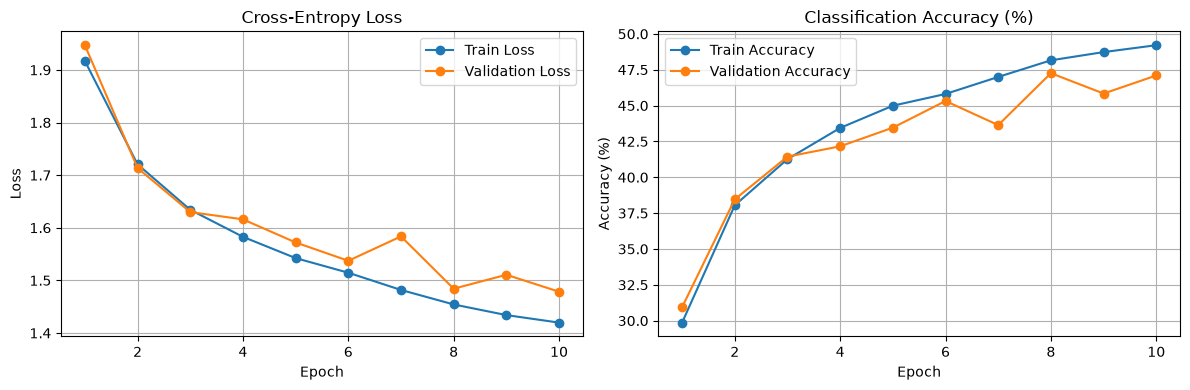


CIFAR-10 Experiment Results:
NeuralNetwork(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Best Validation Loss: 1.4785 | Best Validation Accuracy: 47.10%
Test Loss: 1.4666 | Test Accuracy: 47.59%


In [13]:
params_cifar = {
    # Model and architecture
    "model_type": "MLP",          # "MLP" or "CNN"
    "in_channels": 3,             # 3 RGB channels for CIFAR-10
    "image_size": 32,             # 32x32 image size for CIFAR-10
    "hidden_dims": [128, 64], 
    "cnn_channels": [32, 64],     # Increased channels for 3-channel input
    "kernel_size": 3,
    "pool_size": 2,
    "stride": 2,

    # Activation & Initialization
    "activation": nn.ReLU, 
    "initialization": None,

    # Optimizer
    "optimizer": "SGD",
    "learning_rate": 0.01, 
    "weight_decay": 1e-4,
    "momentum": 0.9,

    # Regularization & Training
    "dropout": 0.0,
    "epochs": 10,
    "batch_size": 64
}

# Run experiment passing CIFAR datasets
model_cifar, history_cifar, best_val_loss_cifar, best_val_acc_cifar, test_loss_cifar, test_acc_cifar = run_experiment(
    params_cifar, 
    train=cifar_train, 
    validation=cifar_validation, 
    test=cifar_test, 
    plotting=True
)

print("\nCIFAR-10 Experiment Results:")
print(model_cifar)
print(f"Best Validation Loss: {best_val_loss_cifar:.4f} | Best Validation Accuracy: {best_val_acc_cifar:.2f}%")
print(f"Test Loss: {test_loss_cifar:.4f} | Test Accuracy: {test_acc_cifar:.2f}%")

# Task 2

## Telling the Time Neural Network

### Pre-processing

**Defining the set seed function and configuring our device** 

In [2]:
# Hardware device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed = 67):
    """Seed every random number generator we use (67 = our group number, as in Task 1)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Using device: cuda


**Loading data: train, validation and test**

In [3]:
clock_images = np.load("data/A1_data_75/images.npy")   # expected (18000, 75, 75): 18000 images of size 75x75
clock_labels = np.load("data/A1_data_75/labels.npy")   # expected (18000, 2): 18000 labels of hour and minute pairs

x = torch.from_numpy(clock_images).float().unsqueeze(1) # converts pixels from unit8 to float and adds a channel dimension (1 because grayscale)
if x.max().item() > 1.0:                                # If pixel values are in range [0, 255], we scale them to [0, 1] for better training stability
    x = x / 255.0

y = torch.from_numpy(clock_labels).long()              # (18000, 2): 18000 labels of hour and minute pairs as tensor

clock_all = TensorDataset(x, y) # Create a TensorDataset from the images and labels

# Splitting the full data set into an 80/10/10 split for training/validation/test in one run. Random_split shuffles the data to fix any ordering in files
n = len(clock_all)
n_train = int(0.8 * n)
n_val = int(0.1 * n)
n_test = n - n_train - n_val

clock_train, clock_validation, clock_test = random_split(
    clock_all,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(67)
)
# Standardize with the mean/std of the TRAINING images only (no leakage from validation/test).
train_idx = clock_train.indices
mean, std = x[train_idx].mean(), x[train_idx].std()
x.sub_(mean).div_(std)
print(f"train mean/std used: {mean:.4f} / {std:.4f}")


train mean/std used: 0.5971 / 0.2176


**Visualizing**

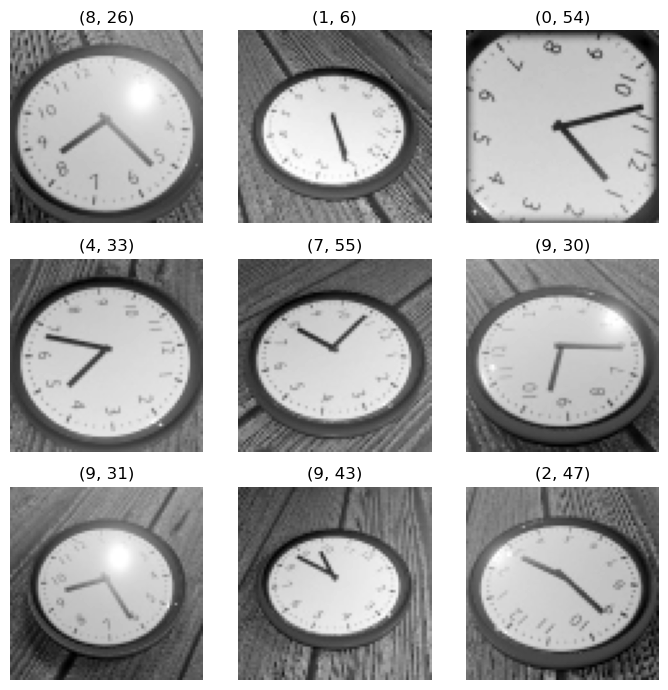

In [4]:
idxs = torch.randperm(len(x))[:9]   # 9 random images

fig, ax = plt.subplots(3, 3, figsize=(7, 7))
for k, idx in enumerate(idxs): # idx is the actual clock/label pair we visualize, k is the index of the subplots we are fitting in the 3x3
    hour, minute = y[idx].tolist()
    ax[k // 3, k % 3].imshow(x[idx, 0], cmap="gray") # k// 3 and k %3 to properly index the 3x3 grid of subplots
    ax[k // 3, k % 3].axis("off")
    ax[k // 3, k % 3].set_title(f"({hour}, {minute})")
plt.tight_layout()
plt.show()

**Dataloader**

We again create the dataloaders. Shuffling is set to true for the training set again to make sure that the batches are random between epochs. For validation and test set since we take the average the order doesn't matter and as such we don't need to shuffle. 

We take the same batch size of Task 1. With 14,400 training images this amounts to 225 updates per epoch. 
We keep the batch size to a moderate 64 to account for the fact that the images, especially in the final run are much larger compared to task 1 (150x150 as opposed to 28x28) and as such take up more space in the memory.

In [5]:
batch_size = 64

clock_train_loader = DataLoader(clock_train, batch_size = batch_size, shuffle = True)
clock_validation_loader = DataLoader(clock_validation, batch_size = batch_size, shuffle = False)
clock_test_loader = DataLoader(clock_test, batch_size = batch_size, shuffle = False)

In [6]:
print(f"Number of batches in the training DataLoader: {len(clock_train_loader)}")
print(f"Number of batches in the validation DataLoader: {len(clock_validation_loader)}")
print(f"Number of batches in the test DataLoader: {len(clock_test_loader)}")
images, labels = next(iter(clock_train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Number of batches in the training DataLoader: 225
Number of batches in the validation DataLoader: 29
Number of batches in the test DataLoader: 29
Image batch shape: torch.Size([64, 1, 75, 75])
Label batch shape: torch.Size([64, 2])
Image data type: torch.float32
Pixel range: -2.3657608032226562 1.8514466285705566


### Evaluation metric: common-sense error

Every time is converted to *minutes since 12:00* (0 to 719). The error is the shorter way around the 12-hour clock, so 11:55 vs 0:05 is 10 minutes, not 11 h 50 min.

In [7]:
def time_in_minutes(labels):
    """Convert (hour, minute) labels into minutes since 12:00, in [0, 720). Hour 12 and hour 0 are the same."""
    return (labels[:, 0] % 12) * 60 + labels[:, 1]

def common_sense_error(pred_minutes, true_minutes):
    """Absolute time difference in minutes, taking the 12-hour wrap-around into account."""
    diff = torch.remainder(pred_minutes - true_minutes, 720)     # in [0, 720), also for negative predictions
    return torch.minimum(diff, 720 - diff)                        # the shorter way around the clock

### Model Building

In this section we build `ClockNet`, a CNN class similar in structure to the `NeuralNetwork` class of Task 1. All four formulations (classification, regression, multi-head and trigonometric encoding) share the same backbone: convolutional blocks followed by fully connected layers. The hyperparameter `output_type` only selects the output layer (head), so one class covers all of the experiments, and only the output layer changes between them. The loss and the conversion of  outputs into time, depend on `output_type` as well and are defined in the next section.

In [8]:
class ClockNet(nn.Module):
    def __init__(self,
            output_type = "regression",     # "classification", "regression", "multihead" or "trig"
            n_classes = 24,                 # classification only: 24 -> 30-minute bins, ..., 720 -> 1-minute bins
            minute_mode = "class",          # multihead only: minute head with 60 classes ("class") or one value ("reg")
            cnn_channels = [32, 64, 128, 256],   # output channels of each convolutional block
            kernel_size = 3,                # padding = kernel_size // 2 keeps the image size, so use odd sizes
            batch_norm = True,
            hidden_dims = [256],            # fully connected layers shared by all heads
            activation = nn.ReLU,
            dropout = 0.0):
        super().__init__()
        self.output_type = output_type

        #---------------Shared convolutional backbone---------------
        layers = []
        in_ch = 1                           # grayscale images
        for out_ch in cnn_channels:
            layers.append(nn.Conv2d(in_ch, out_ch, kernel_size, padding = kernel_size // 2))
            if batch_norm:
                # Batch normalization: normalizes each channel of the conv output (zero mean, unit variance over the batch),
                # then rescales it with learnable parameters. It keeps activations on a stable scale between layers. This ultimately
                # speeds up training and makes it less sensitive to the learning rate and initialization.
                layers.append(nn.BatchNorm2d(out_ch))
            layers.append(activation())
            layers.append(nn.MaxPool2d(2))
            in_ch = out_ch
        self.features = nn.Sequential(*layers)

        # Fixed 4x4 feature map before the linear layers, so the same network accepts 75x75 and 150x150 images.
        # We keep a 4x4 map instead of one average per channel (1x1), because the position of the clock hands carries the information.
        self.pool = nn.AdaptiveAvgPool2d(4)

        #---------------Shared fully connected layers---------------
        fc_layers = [nn.Flatten()]
        input_size = cnn_channels[-1] * 4 * 4
        for hidden_size in hidden_dims:
            fc_layers.append(nn.Linear(input_size, hidden_size))
            fc_layers.append(activation())
            if dropout > 0:
                fc_layers.append(nn.Dropout(dropout))
            input_size = hidden_size
        self.fc = nn.Sequential(*fc_layers)

        #---------------Output head(s): no activation, they output logits / raw values---------------
        if output_type == "classification":
            self.head = nn.Linear(input_size, n_classes)    # one score (logit) per time bin
        elif output_type == "regression":
            self.head = nn.Linear(input_size, 1)            # time as a fraction of 12 hours
        elif output_type == "trig":
            self.head = nn.Linear(input_size, 4)        # sin / cos of the hour angle and of the minute angle
        elif output_type == "multihead":                # two heads: hour and minute
            self.hour_head = nn.Linear(input_size, 12)  # 12 classes for the hour (0-11)
            self.minute_head = nn.Linear(input_size, 60 if minute_mode == "class" else 1) # 60 classes for the minute (0-59) or 1 value for regression
        else:
            raise ValueError(f"Unknown output_type: {output_type!r}")

    def forward(self, x):
        z = self.fc(self.pool(self.features(x)))        # representation shared by all heads
        if self.output_type == "multihead":
            return self.hour_head(z), self.minute_head(z)       # out_hour, out_minute = model(x)
        out = self.head(z)
        if self.output_type == "trig":
            # Scale each (sin, cos) pair to length 1: the prediction is then a point on the unit circle.
            # (No ReLU / sigmoid: sin and cos can be negative.)
            out = torch.cat([F.normalize(out[:, :2], dim = 1), F.normalize(out[:, 2:], dim = 1)], dim = 1)
        return out

### Targets, losses and decoding

For every formulation we need (1) the **target** that is built from the (hour, minute) label, (2) the **loss**, and (3) a way to turn the network output back into a time in minutes, so that all formulations are scored with the same common-sense error.

In [9]:
# Losses for outputs that are real numbers (regression, minute head, trigonometric encoding).
# SmoothL1 uses beta = 0.05 instead of the default 1.0: our targets are in [0, 1], so with beta = 1
# SmoothL1 would simply be 0.5 * MSE.
# MSE penalizes large errors heavily (sensitive to outliers such as a hand mistaken by 180 degrees), L1 treats all errors
# linearly (robust, and directly matches the minutes-based metric), SmoothL1 is quadratic for small errors and linear for large ones.
REG_LOSSES = {"mse": nn.MSELoss(), "l1": nn.L1Loss(), "smoothl1": nn.SmoothL1Loss(beta = 0.05)}

def trig_encode(labels):
    """(hour, minute) -> (sin, cos) of the hour-hand angle and of the minute-hand angle, shape (B, 4)."""
    # The hour hand makes one full turn in 12 hours (720 min) and moves gradually with the minutes,
    # the minute hand makes one full turn in 60 minutes. Mapping to the unit circle makes 11:59 and 0:01 neighbours.
    angle_h = 2 * math.pi * time_in_minutes(labels).float() / 720       # = 2 pi (hour + minute / 60) / 12
    angle_m = 2 * math.pi * labels[:, 1].float() / 60
    return torch.stack([torch.sin(angle_h), torch.cos(angle_h), torch.sin(angle_m), torch.cos(angle_m)], dim = 1)

def compute_loss(outputs, labels, params): # outputs: model predictions, labels: true (hour, minute) pairs, params: dictionary of hyperparameters
    # Turns the true labels into the target of the chosen formulation and compares it with the network output.
    kind = params["output_type"]
    t = time_in_minutes(labels).float()                  # true time in minutes since 12:00
    hour, minute = labels[:, 0] % 12, labels[:, 1]       # % 12: hour 12 and hour 0 are the same class (0-11)

    if kind == "classification":
        # Divide the 12 hours (720 min) into n_classes equal bins, e.g. 24 classes -> 30-minute bins.
        # F.cross_entropy applies softmax itself, so the network outputs raw logits and needs no final activation.
        bin_size = 720 // params["n_classes"]
        return F.cross_entropy(outputs, (t // bin_size).long())          # class = index of the time bin

    if kind == "regression":
        # params["loss"] ("mse", "l1" or "smoothl1") selects the loss object from the REG_LOSSES dictionary, which is then
        # called as loss(prediction, target). squeeze(1) turns the (batch, 1) output into (batch,) to match the target.
        return REG_LOSSES[params["loss"]](outputs.squeeze(1), t / 720)   # target: fraction of 12 hours, in [0, 1)

    if kind == "multihead":
        # The model returns two outputs: 12 hour logits and a minute output (60 logits or one value).
        out_hour, out_minute = outputs
        loss_hour = F.cross_entropy(out_hour, hour)                      # hour: always 12-class classification
        if params["minute_mode"] == "class":
            loss_minute = F.cross_entropy(out_minute, minute)            # minute as 60-class classification
        else:
            loss_minute = REG_LOSSES[params["loss"]](out_minute.squeeze(1), minute / 60)   # minute as regression on [0, 1)
        # Joint loss L = L_hour + alpha * L_minute. Both gradients flow into the shared backbone, and the two losses have
        # different scales (cross-entropy vs. a regression loss), so alpha balances how much each head influences it.
        return loss_hour + params["alpha"] * loss_minute

    if kind == "trig":
        # Compare the predicted (sin, cos) pairs of both hands with the true ones. No jump at 12:00,
        # because 11:59 and 0:01 have almost the same target on the unit circle.
        return REG_LOSSES[params["loss"]](outputs, trig_encode(labels))

def outputs_to_minutes(outputs, params):
    """Turn network outputs into a predicted time in minutes since 12:00 (the wrap-around is handled by common_sense_error)."""
    # Inverse of compute_loss: lets all formulations be scored with the same metric.
    kind = params["output_type"]

    if kind == "classification":
        bin_size = 720 // params["n_classes"]
        return outputs.argmax(1).float() * bin_size + (bin_size - 1) / 2      # centre of the predicted bin

    if kind == "regression":
        return outputs.squeeze(1) * 720                                       # undo the scaling to [0, 1)

    if kind == "multihead":
        out_hour, out_minute = outputs
        if params["minute_mode"] == "class":
            minute = out_minute.argmax(1).float()
        else:
            minute = out_minute.squeeze(1) * 60                               # undo the scaling to [0, 1)
        return out_hour.argmax(1).float() * 60 + minute                       # hour and minute are decided independently

    if kind == "trig":
        # atan2(sin, cos) recovers each hand's angle; % 2 pi maps it to [0, 2 pi)
        angle_h = torch.atan2(outputs[:, 0], outputs[:, 1]) % (2 * math.pi)     # hour-hand angle in [0, 2 pi)
        angle_m = torch.atan2(outputs[:, 2], outputs[:, 3]) % (2 * math.pi)     # minute-hand angle
        rough = angle_h / (2 * math.pi) * 720          # rough time from the hour hand
        minute = angle_m / (2 * math.pi) * 60          # exact minute from the minute hand
        # The hour hand only gives a rough time, the minute hand the exact minute.
        # Pick the hour h (0..11) for which 60 * h + minute is closest to the rough time.
        hours = torch.arange(12, device = outputs.device).float().view(1, 12)
        candidates = hours * 60 + minute.view(-1, 1)                            # (B, 12): the 12 possible times
        diff = torch.remainder(candidates - rough.view(-1, 1), 720)             # circular distance to the hour-hand estimate
        diff = torch.minimum(diff, 720 - diff)
        return candidates.gather(1, diff.argmin(1, keepdim = True)).squeeze(1)  # keep the closest candidate

In [10]:
# Perfect trigonometric outputs must decode back to the true time (error ~ 0)
check = torch.tensor([[0, 5], [11, 55], [3, 0], [2, 34], [7, 59]])      # (hour, minute)
decoded = outputs_to_minutes(trig_encode(check), {"output_type": "trig"})
print(common_sense_error(decoded, time_in_minutes(check).float()))

tensor([0., 0., 0., 0., 0.])


### Training

`run_experiment` has the same structure as in Task 1: parameters in a dict, DataLoaders, model, optimizer, training / validation loop, restore of the best weights, test evaluation. Differences:
* The loss and the prediction depend on `output_type` and the metric is the common-sense error in minutes instead of the accuracy.
* The best epoch is the one with the lowest **validation error** (the metric we want to minimise; the losses of different formulations cannot be compared).
* The test set is only evaluated when `evaluate_test = True`, so we do not pick hyperparameters with it.

In [11]:
def make_optimizer(model, name, learning_rate, weight_decay = 0.0, momentum = 0.9):
    if name == "SGD":
        return optim.SGD(model.parameters(), lr = learning_rate, momentum = momentum, weight_decay = weight_decay)
    if name == "Adam":
        return optim.Adam(model.parameters(), lr = learning_rate, weight_decay = weight_decay)
    if name == "AdamW":
        return optim.AdamW(model.parameters(), lr = learning_rate, weight_decay = weight_decay)
    raise ValueError(f"Unknown optimizer: {name!r}")

@torch.no_grad()        # no gradients needed for evaluation: saves memory and time
def evaluate(model, loader, params):
    """Average loss, mean common-sense error, and the per-image predicted / true times (in minutes)."""
    model.eval()        # BatchNorm uses its running statistics and dropout is switched off
    loss_total, n = 0.0, 0
    preds, trues = [], []
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        # compute_loss returns the batch mean, so we multiply by the batch size: the last batch is smaller,
        # and this gives the exact average over all images
        loss_total += compute_loss(outputs, labels, params).item() * labels.size(0)
        n += labels.size(0)
        # Convert every formulation to minutes, so all of them are scored with the same metric
        preds.append(outputs_to_minutes(outputs, params).cpu())
        trues.append(time_in_minutes(labels).float().cpu())
    preds, trues = torch.cat(preds), torch.cat(trues)
    mean_error = common_sense_error(preds, trues).mean().item()
    # preds / trues are returned too, for the error analysis (e.g. region_errors and the plots at the end)
    return loss_total / n, mean_error, preds, trues

def region_errors(pred, true, window = 30):
    """Mean error for times within `window` minutes of 12:00 (where the 12 -> 0 wrap-around is) and for all other times."""
    # Used to check whether a formulation struggles at the 12:00 boundary (e.g. plain regression, which does not know
    # that the clock is circular) compared to the rest of the clock face.
    error = common_sense_error(pred, true)
    near = (true < window) | (true > 720 - window)
    return error[near].mean().item(), error[~near].mean().item()

def plot_history(history):
    # Left: loss (the training objective, not comparable between formulations). Right: common-sense error in minutes,
    # the metric we actually want to minimise. It is comparable between formulations. A growing gap between train and validation indicates overfitting.
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4))

    # Loss Plot
    ax1.plot(epochs_range, history["train_loss"], marker = "o", label = "Train Loss")
    ax1.plot(epochs_range, history["val_loss"], marker = "o", label = "Validation Loss")
    ax1.set_title("Training loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    # Error Plot
    ax2.plot(epochs_range, history["train_err"], marker = "o", label = "Train Error")
    ax2.plot(epochs_range, history["val_err"], marker = "o", label = "Validation Error")
    ax2.set_title("Common-sense error")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Error (minutes)")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

`run_experiment` follows the same structure as the training function of Task 1: hyperparameters in a dictionary, DataLoaders, model and optimizer, a training and validation loop, restoring the best weights, and an optional test evaluation. The differences are:

* **Formulation-dependent loss and prediction.** The loss comes from `compute_loss`, and the predictions are converted to minutes with `outputs_to_minutes`. The metric is the common-sense error in minutes, not the accuracy.
* **Best epoch by validation error.** The model we keep is the one with the lowest validation error, since that is the quantity we want to minimize. The losses of different formulations cannot be compared with each other.
* **Learning rate schedule.** We add a cosine decay of the learning rate over all epochs.
* **Test set on request only.** The test set is evaluated only with `evaluate_test = True`, so it is never used to choose hyperparameters.
* **Per-image predictions.** The best model's predictions are stored in `history`, which is used for the error analysis (errors near 12:00, error histograms, example images).

In [12]:
# The hyperparameters that ClockNet.__init__ needs. The params dictionary also holds training settings
# (learning rate, epochs, ...), so we only pass these keys on to the model.
MODEL_KEYS = ("output_type", "n_classes", "minute_mode", "cnn_channels", "kernel_size",
              "batch_norm", "hidden_dims", "activation", "dropout")

def run_experiment(params, train = None, validation = None, test = None,
                   plotting = False, evaluate_test = False, verbose = False):
    # By default we use the 75x75 datasets
    train = clock_train if train is None else train
    validation = clock_validation if validation is None else validation
    test = clock_test if test is None else test

    # Seeding at the start of every run makes the runs reproducible and comparable (same initial weights and batch order)
    set_seed(params["seed"])
    if params["output_type"] == "classification":
        # The bin size is 720 // n_classes, so n_classes must divide 720 to give equal bins
        assert 720 % params["n_classes"] == 0, "n_classes must divide 720 (24, 72, 144, 720, ...)"
    start_time = time.time()

    # Create DataLoaders (shuffle only the training data; the order of validation / test data stays fixed,
    # so the predictions line up with the images, which is needed for the plots at the end)
    train_loader = DataLoader(train, batch_size = params["batch_size"], shuffle = True)
    validation_loader = DataLoader(validation, batch_size = params["batch_size"], shuffle = False)
    test_loader = DataLoader(test, batch_size = params["batch_size"], shuffle = False)

    # Create the model and the optimizer (only the keys the model needs are passed on)
    model = ClockNet(**{key: params[key] for key in MODEL_KEYS}).to(device)
    optimizer = make_optimizer(model, params["optimizer"], params["learning_rate"], params["weight_decay"])

    # Learning rate schedule: cosine decay from the learning rate to 0 over all epochs
    # (large steps early on, small steps at the end for fine convergence)
    scheduler = None
    if params["scheduler"] == "cosine":
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max = params["epochs"])

    # Store losses and errors for each epoch
    history = {"train_loss": [], "val_loss": [], "train_err": [], "val_err": []}
    best_val_loss, best_val_err, best_epoch, best_model_state = np.inf, np.inf, 0, None

    for epoch in range(params["epochs"]):
        #---------- Training Phase ----------
        model.train()
        loss_total, err_total, n = 0.0, 0.0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = compute_loss(outputs, labels, params)       # the loss depends on the formulation (output_type)
            loss.backward()
            optimizer.step()

            # Training performance (a running average over the epoch, measured in train mode)
            loss_total += loss.item() * labels.size(0)
            with torch.no_grad():       # only for measuring, not part of the training
                err = common_sense_error(outputs_to_minutes(outputs, params), time_in_minutes(labels).float())
            err_total += err.sum().item()
            n += labels.size(0)

        history["train_loss"].append(loss_total / n)
        history["train_err"].append(err_total / n)

        #---------- Validation Phase ----------
        val_loss, val_err, _, _ = evaluate(model, validation_loader, params)
        history["val_loss"].append(val_loss)
        history["val_err"].append(val_err)

        # The scheduler is stepped once per epoch, after the optimizer updates of that epoch
        if scheduler is not None:
            scheduler.step()

        if verbose:
            print(f"Epoch {epoch + 1:>3}/{params['epochs']} | train loss {history['train_loss'][-1]:.4f} | "
                  f"val loss {val_loss:.4f} | train err {history['train_err'][-1]:.1f} | val err {val_err:.1f} min")

        # Save the model with the lowest validation ERROR (not loss: the losses of different formulations are not
        # comparable, and the error is what we want to minimise). The weights are copied to the CPU, because
        # state_dict() returns references that would otherwise be overwritten by the next training steps.
        if val_err < best_val_err:
            best_val_loss, best_val_err, best_epoch = val_loss, val_err, epoch + 1
            best_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

        # Stop if training diverged (NaN / inf), e.g. with a learning rate that is too high
        if not np.isfinite(val_loss):
            break

    # Restore the best weights, so the model we return and evaluate is the best epoch, not the last one
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    history["best_epoch"] = best_epoch

    # Per-image predictions of the best model on the validation set (used for the error analysis)
    _, _, history["val_pred"], history["val_true"] = evaluate(model, validation_loader, params)

    #---------- Test Phase (only on request) ----------
    # Only evaluated for the final runs, so hyperparameters are never chosen using the test set
    test_loss, test_err = None, None
    if evaluate_test:
        test_loss, test_err, history["test_pred"], history["test_true"] = evaluate(model, test_loader, params)

    print(f"  done in {time.time() - start_time:.0f}s | best validation error {best_val_err:.2f} min (epoch {best_epoch})")
    if plotting:
        plot_history(history)

    # Test values are None unless evaluate_test = True
    return model, history, best_val_loss, best_val_err, test_loss, test_err

### Grid search

`run_grid` runs `run_experiment` for every combination of the values in a grid, e.g. `{"loss": ["mse", "l1"]}` or `{"learning_rate": [1e-3, 3e-4], "dropout": [0.0, 0.3]}`, on top of a set of base parameters. It returns a table of the results (best first) and the parameters of the best run. Besides the validation error, the table shows the error near 12:00 and elsewhere, to see whether a setting struggles at the wrap-around. Only the validation set is used.

In [13]:
def run_grid(base_params, grid):
    """Run every combination of the values in `grid` ({parameter name: list of values}) on top of `base_params`.
    Returns a results table (best first) and the parameters of the best run."""
    rows, best_err, best_params = [], np.inf, None

    # itertools.product gives every combination of the lists, e.g. 2 learning rates x 2 dropouts = 4 runs
    for values in itertools.product(*grid.values()):
        changes = dict(zip(grid.keys(), values))       # the settings of this run, e.g. {"loss": "l1"}
        print("Testing ->", changes)
        params = {**base_params, **changes}            # the changes override the base parameters

        # Only the validation set is used here (run_experiment does not touch the test set by default)
        model, history, val_loss, val_err, _, _ = run_experiment(params)
        # Split the error into times near 12:00 (wrap-around region) and all other times
        near, elsewhere = region_errors(history["val_pred"], history["val_true"])
        rows.append({
            "Formulation": params["output_type"],
            "Setting": ", ".join(f"{key}={value}" for key, value in changes.items()),
            "Val Err (min)": round(val_err, 2),
            "Err near 12:00": round(near, 2),
            "Err elsewhere": round(elsewhere, 2),
            "Best epoch": history["best_epoch"],
            "Params": sum(p.numel() for p in model.parameters()),       # model size, to see the cost of wider networks
        })
        # Keep the full parameter dictionary of the run with the lowest validation error, so it can be reused later
        if best_params is None or val_err < best_err:
            best_err, best_params = val_err, params

    results = pd.DataFrame(rows).sort_values("Val Err (min)").reset_index(drop = True)
    return results, best_params

## Experiments on the 75x75 images (validation set)

Parameters

* Output: `output_type` ("classification", "regression", "multihead", "trig"), `n_classes`, `minute_mode`, `alpha`, `loss` ("mse", "l1", "smoothl1")
* Architecture: `cnn_channels`, `kernel_size`, `batch_norm`, `hidden_dims`, `activation`, `dropout`
* Optimizer: `optimizer`, `learning_rate`, `weight_decay`, `scheduler`
* Training: `epochs`, `batch_size`, `seed`

First a baseline (regression with the L1 loss) with training curves.

Epoch   1/20 | train loss 0.3735 | val loss 0.2330 | train err 174.9 | val err 160.3 min
Epoch   2/20 | train loss 0.2077 | val loss 0.1859 | train err 144.0 | val err 129.5 min
Epoch   3/20 | train loss 0.1730 | val loss 0.1642 | train err 120.6 | val err 114.4 min
Epoch   4/20 | train loss 0.1508 | val loss 0.1452 | train err 105.7 | val err 101.8 min
Epoch   5/20 | train loss 0.1274 | val loss 0.1162 | train err 89.8 | val err 81.3 min
Epoch   6/20 | train loss 0.1063 | val loss 0.1061 | train err 75.3 | val err 75.3 min
Epoch   7/20 | train loss 0.0932 | val loss 0.1291 | train err 66.1 | val err 89.5 min
Epoch   8/20 | train loss 0.0856 | val loss 0.0857 | train err 60.9 | val err 60.9 min
Epoch   9/20 | train loss 0.0741 | val loss 0.0787 | train err 52.8 | val err 55.7 min
Epoch  10/20 | train loss 0.0675 | val loss 0.0789 | train err 48.4 | val err 56.2 min
Epoch  11/20 | train loss 0.0598 | val loss 0.0657 | train err 42.9 | val err 46.8 min
Epoch  12/20 | train loss 0.0541 | 

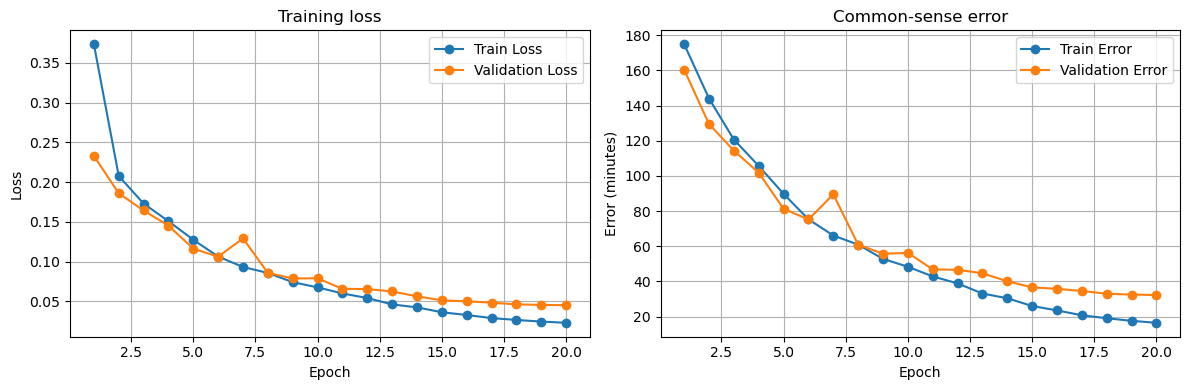


Baseline results:
Best Validation Error: 32.25 minutes (epoch 20) | Parameters: 1,437,889


In [14]:
base_params = {
    # Output formulation
    "output_type": "regression",    # "classification", "regression", "multihead" or "trig"
    "n_classes": 24,                # only for classification (must divide 720)
    "minute_mode": "class",         # only for multihead: "class" (60 classes) or "reg" (one value)
    "alpha": 1.0,                   # only for multihead: L = L_hour + alpha * L_minute
    "loss": "l1",                   # for real-valued outputs: "mse", "l1" or "smoothl1"

    # Architecture
    "cnn_channels": [32, 64, 128, 256],
    "kernel_size": 3,
    "batch_norm": True,
    "hidden_dims": [256],
    "activation": nn.ReLU,
    "dropout": 0.0,

    # Optimizer
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "weight_decay": 0.0,
    "scheduler": "cosine",          # "cosine" or None

    # Training
    "epochs": 20,
    "batch_size": 64,
    "seed": 67
}

model0, history0, val_loss0, val_err0, _, _ = run_experiment(base_params, plotting = True, verbose = True)

print("\nBaseline results:")
print(f"Best Validation Error: {val_err0:.2f} minutes (epoch {history0['best_epoch']}) | Parameters: {sum(p.numel() for p in model0.parameters()):,}")

### 1. Classification

Bins of 30 / 10 / 5 / 1 minutes (24 / 72 / 144 / 720 classes). The predicted time is the centre of the predicted bin.

*For the report:* what happens to the error when the number of classes grows? Think about the number of training images per class (14,400 / 720 = 20), about neighbouring classes being treated as completely unrelated by the cross-entropy loss, and about the size of the output layer.

In [15]:
grid_cls = {"n_classes": [24, 72, 144, 720]}
results_cls, best_cls = run_grid({**base_params, "output_type": "classification"}, grid_cls)
display(results_cls)

Testing -> {'n_classes': 24}
  done in 131s | best validation error 9.93 min (epoch 20)
Testing -> {'n_classes': 72}
  done in 131s | best validation error 25.43 min (epoch 20)
Testing -> {'n_classes': 144}
  done in 131s | best validation error 175.02 min (epoch 1)
Testing -> {'n_classes': 720}
  done in 131s | best validation error 178.27 min (epoch 1)


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,classification,n_classes=24,9.93,10.23,9.91,20,1443800
1,classification,n_classes=72,25.43,20.49,25.82,20,1456136
2,classification,n_classes=144,175.02,177.71,174.81,1,1474640
3,classification,n_classes=720,178.27,88.82,185.35,1,1622672


### 2. Regression

One output (time as a fraction of 12 hours). Which loss is best? Look at the columns **Err near 12:00** (true time within 30 minutes of 12:00) and **Err elsewhere**.

*For the report:* 11:59 and 0:01 are 2 minutes apart, but as numbers they are almost the whole range apart (0.998 vs 0.001). The loss cannot know that the clock is circular, and the images around 12:00 look almost identical, so the network is pulled towards both ends.

In [16]:
grid_reg = {"loss": ["mse", "l1", "smoothl1"]}
results_reg, best_reg = run_grid({**base_params, "output_type": "regression"}, grid_reg)
display(results_reg)

Testing -> {'loss': 'mse'}
  done in 131s | best validation error 72.93 min (epoch 20)
Testing -> {'loss': 'l1'}
  done in 131s | best validation error 32.16 min (epoch 20)
Testing -> {'loss': 'smoothl1'}
  done in 131s | best validation error 32.97 min (epoch 20)


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,regression,loss=l1,32.16,84.45,28.02,20,1437889
1,regression,loss=smoothl1,32.97,82.54,29.05,20,1437889
2,regression,loss=mse,72.93,156.15,66.35,20,1437889


### 3. Multi-head

Shared backbone, two heads: `out_hour, out_minute = model(x)`. The hour head always classifies the 12 hours. The minute head either classifies the 60 minutes (`"class"`) or regresses `minute / 60` (`"reg"`). Joint loss: L = L_hour + alpha x L_minute. The cross-entropy and the regression loss have a different scale, so alpha is explored for both.

*For the report:* compare with the single-output models above. Which mistakes are typical (hint: around the full hour, when the hour hand is almost on a number and the hour and minute heads can disagree)?

In [17]:
grid_multi = {"minute_mode": ["class", "reg"], "alpha": [0.5, 1.0, 5.0]}
results_multi, best_multi = run_grid({**base_params, "output_type": "multihead"}, grid_multi)
display(results_multi)

Testing -> {'minute_mode': 'class', 'alpha': 0.5}
  done in 131s | best validation error 6.64 min (epoch 19)
Testing -> {'minute_mode': 'class', 'alpha': 1.0}
  done in 131s | best validation error 20.52 min (epoch 18)
Testing -> {'minute_mode': 'class', 'alpha': 5.0}
  done in 131s | best validation error 177.32 min (epoch 4)
Testing -> {'minute_mode': 'reg', 'alpha': 0.5}
  done in 131s | best validation error 8.58 min (epoch 20)
Testing -> {'minute_mode': 'reg', 'alpha': 1.0}
  done in 131s | best validation error 7.89 min (epoch 20)
Testing -> {'minute_mode': 'reg', 'alpha': 5.0}
  done in 131s | best validation error 8.08 min (epoch 20)


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,multihead,"minute_mode=class, alpha=0.5",6.64,6.27,6.67,19,1456136
1,multihead,"minute_mode=reg, alpha=1.0",7.89,9.18,7.78,20,1440973
2,multihead,"minute_mode=reg, alpha=5.0",8.08,7.29,8.14,20,1440973
3,multihead,"minute_mode=reg, alpha=0.5",8.58,8.52,8.59,20,1440973
4,multihead,"minute_mode=class, alpha=1.0",20.52,23.18,20.31,18,1456136
5,multihead,"minute_mode=class, alpha=5.0",177.32,205.82,175.06,4,1456136


### 4. Trigonometric encoding

The hands are angles, so we predict the points on the unit circle (sin, cos) of the hour-hand angle and of the minute-hand angle. Design of the output layer (see `ClockNet`):
* 4 linear outputs, no ReLU / sigmoid (sin and cos are in [-1, 1] and can be negative).
* Each (sin, cos) pair is scaled to length 1, so the output is a valid point on the circle. Loss: MSE or L1 against the true (sin, cos).
* Decoding: `atan2` gives the two angles. The minute comes from the minute hand (exact), the hour from the hour hand (rough): we choose the hour for which the time fits the hour hand best. Because 11:59 and 0:01 are neighbours on the circle, there is no discontinuity at 12:00.

In [18]:
grid_trig = {"loss": ["mse", "l1"]}
results_trig, best_trig = run_grid({**base_params, "output_type": "trig"}, grid_trig)
display(results_trig)

Testing -> {'loss': 'mse'}
  done in 132s | best validation error 3.20 min (epoch 20)
Testing -> {'loss': 'l1'}
  done in 132s | best validation error 1.83 min (epoch 20)


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,trig,loss=l1,1.83,2.65,1.76,20,1438660
1,trig,loss=mse,3.20,3.86,3.14,20,1438660


### Comparison of the formulations (validation set)

The best run of every formulation, and the winner.

In [19]:
best_configs = {"classification": best_cls, "regression": best_reg, "multihead": best_multi, "trig": best_trig}

all_results = pd.concat([results_cls, results_reg, results_multi, results_trig])
all_results = all_results.sort_values("Val Err (min)").reset_index(drop = True)
display(all_results)

summary = all_results.drop_duplicates("Formulation").reset_index(drop = True)    # best run per formulation
display(summary)

winner = summary.loc[0, "Formulation"]
print("Best formulation on the validation set:", winner)

,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,trig,loss=l1,1.83,2.65,1.76,20,1438660
1,trig,loss=mse,3.20,3.86,3.14,20,1438660
2,multihead,"minute_mode=class, alpha=0.5",6.64,6.27,6.67,19,1456136
3,multihead,"minute_mode=reg, alpha=1.0",7.89,9.18,7.78,20,1440973
4,multihead,"minute_mode=reg, alpha=5.0",8.08,7.29,8.14,20,1440973
5,multihead,"minute_mode=reg, alpha=0.5",8.58,8.52,8.59,20,1440973
6,classification,n_classes=24,9.93,10.23,9.91,20,1443800
7,multihead,"minute_mode=class, alpha=1.0",20.52,23.18,20.31,18,1456136
8,classification,n_classes=72,25.43,20.49,25.82,20,1456136
9,regression,loss=l1,32.16,84.45,28.02,20,1437889


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,trig,loss=l1,1.83,2.65,1.76,20,1438660
1,multihead,"minute_mode=class, alpha=0.5",6.64,6.27,6.67,19,1456136
2,classification,n_classes=24,9.93,10.23,9.91,20,1443800
3,regression,loss=l1,32.16,84.45,28.02,20,1437889


Best formulation on the validation set: trig


### Backbone tuning

Learning rate, width and dropout for the winning formulation (a small grid; add `weight_decay`, `kernel_size`, ... if you have time).

In [20]:
grid_backbone = {
    "learning_rate": [1e-3, 3e-4],
    "cnn_channels": [[32, 64, 128, 256], [64, 128, 256, 512]],
    "dropout": [0.0, 0.3]
}
results_backbone, best_backbone = run_grid(best_configs[winner], grid_backbone)
display(results_backbone)

Testing -> {'learning_rate': 0.001, 'cnn_channels': [32, 64, 128, 256], 'dropout': 0.0}
  done in 132s | best validation error 2.34 min (epoch 20)
Testing -> {'learning_rate': 0.001, 'cnn_channels': [32, 64, 128, 256], 'dropout': 0.3}
  done in 131s | best validation error 11.78 min (epoch 19)
Testing -> {'learning_rate': 0.001, 'cnn_channels': [64, 128, 256, 512], 'dropout': 0.0}
  done in 273s | best validation error 3.30 min (epoch 19)
Testing -> {'learning_rate': 0.001, 'cnn_channels': [64, 128, 256, 512], 'dropout': 0.3}
  done in 272s | best validation error 8.26 min (epoch 20)
Testing -> {'learning_rate': 0.0003, 'cnn_channels': [32, 64, 128, 256], 'dropout': 0.0}
  done in 132s | best validation error 4.52 min (epoch 18)
Testing -> {'learning_rate': 0.0003, 'cnn_channels': [32, 64, 128, 256], 'dropout': 0.3}
  done in 131s | best validation error 17.50 min (epoch 20)
Testing -> {'learning_rate': 0.0003, 'cnn_channels': [64, 128, 256, 512], 'dropout': 0.0}
  done in 272s | best 

,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,trig,"learning_rate=0.0003, cnn_channels=[64, 128, 2...",2.32,2.34,2.32,19,3650180
1,trig,"learning_rate=0.001, cnn_channels=[32, 64, 128...",2.34,2.33,2.34,20,1438660
2,trig,"learning_rate=0.001, cnn_channels=[64, 128, 25...",3.30,3.16,3.31,19,3650180
3,trig,"learning_rate=0.0003, cnn_channels=[32, 64, 12...",4.52,3.77,4.58,18,1438660
4,trig,"learning_rate=0.0003, cnn_channels=[64, 128, 2...",6.04,5.96,6.05,20,3650180
5,trig,"learning_rate=0.001, cnn_channels=[64, 128, 25...",8.26,8.79,8.22,20,3650180
6,trig,"learning_rate=0.001, cnn_channels=[32, 64, 128...",11.78,9.30,11.97,19,1438660
7,trig,"learning_rate=0.0003, cnn_channels=[32, 64, 12...",17.50,14.86,17.71,20,1438660


## Final results on the 150x150 images (test set)

All four formulations are trained on the 150x150 images with their best settings from above and the tuned backbone. We select the final model with the **validation** error; the test error is only reported.

In [ ]:
final_epochs = 30
clock150_train, clock150_validation, clock150_test = load_clock_data(150)

tuned = {key: best_backbone[key] for key in ("learning_rate", "cnn_channels", "dropout")}
final_rows, final_runs = [], {}

for name, config in best_configs.items():
    print(f"Final training -> {name}")
    params = {**config, **tuned, "epochs": final_epochs}
    model, history, val_loss, val_err, test_loss, test_err = run_experiment(
        params, clock150_train, clock150_validation, clock150_test, evaluate_test = True, verbose = True)

    near, elsewhere = region_errors(history["test_pred"], history["test_true"])
    final_rows.append({
        "Formulation": name,
        "Val Err (min)": round(val_err, 2),
        "Test Err (min)": round(test_err, 2),
        "Test near 12:00": round(near, 2),
        "Test elsewhere": round(elsewhere, 2)
    })
    final_runs[name] = (model, history)

final_table = pd.DataFrame(final_rows).sort_values("Val Err (min)").reset_index(drop = True)
display(final_table)

### Error analysis of the final model

In [ ]:
best_name = final_table.loc[0, "Formulation"]
final_model, final_history = final_runs[best_name]
errors = common_sense_error(final_history["test_pred"], final_history["test_true"])

print(f"Final model: {best_name}")
print(f"Test error: mean {errors.mean():.2f} | median {errors.median():.2f} | 90th percentile {errors.quantile(0.9):.2f} minutes")
for tolerance in (1, 5, 10, 30):
    print(f"Within {tolerance:>2} minutes: {100 * (errors <= tolerance).float().mean():.1f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4))
ax1.hist(errors.numpy(), bins = 50)
ax1.set_title("Distribution of the test errors")
ax1.set_xlabel("Common-sense error (minutes)")
ax1.set_ylabel("Number of test images")

ax2.scatter(final_history["test_true"].numpy() / 60, errors.numpy(), s = 5)
ax2.set_title("Error versus true time")
ax2.set_xlabel("True time (hours since 12:00)")
ax2.set_ylabel("Common-sense error (minutes)")
plt.tight_layout()
plt.show()

In [ ]:
def clock_string(minutes):
    minutes = int(round(float(minutes))) % 720
    return f"{minutes // 60}:{minutes % 60:02d}"

# Some test images with the true and the predicted time
fig, ax = plt.subplots(3, 3, figsize = (9, 9))
for i, axis in enumerate(ax.flatten()):
    image, _ = clock150_test[i]
    axis.imshow(image.squeeze(), cmap = "gray")
    axis.set_title(f"true {clock_string(final_history['test_true'][i])} | pred {clock_string(final_history['test_pred'][i])} "
                   f"| error {errors[i]:.0f} min", fontsize = 8)
    axis.axis("off")
plt.tight_layout()
plt.show()

torch.save(final_model.state_dict(), "clock_model.pt")